# MissForest reproduction: Isoprenoid gene network (Arabidopsis thaliana)

Reproduces the first continuous-data experiment of Stekhoven and Bühlmann (2012), *MissForest: non-parametric missing value imputation for mixed-type data*, Bioinformatics 28(1):112-118 (Fig. 1, top dataset).

**Experiment.** Remove 10, 20 and 30% of the values completely at random, impute with MissForest and with cross-validated KNNimpute, compute NRMSE on the removed entries, repeat 50 times, and compare with a paired Wilcoxon test. The out-of-bag (OOB) error estimate of MissForest is recorded in every run.

**How to use.** Set `CSV_PATH` in the first code cell and run all cells (*Kernel > Restart & Run All*). Only the Python packages numpy, pandas, scipy, scikit-learn and matplotlib are needed. The full run (50 runs x 3 rates) can take a while, so set `NSIM = 5` first to check that everything works.

In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import KNNImputer

# ---------------- settings (edit here) ----------------
CSV_PATH = "content.csv"   # path to your CSV file
HEADER   = "infer"            # use None if the file has no header row
NSIM     = 10            # simulation runs per missing rate (paper: 50)
RATES    = [0.10, 0.20, 0.30] # fraction of values removed (paper: 10, 20, 30%)
NTREE    = 100                # trees per forest (paper: 100)
MTRY     = None               # variables tried per split; None = floor(sqrt(p)) (paper)
MAXITER  = 10                 # cap on MissForest iterations (assumption, not given in the paper)
KS       = range(1, 16)       # candidate k for KNNimpute (paper: 1..15)
KNN_NEIGHBOURS = "variables"  # "variables" = neighbours among genes, as in the paper; "samples" = rows
SEED     = 42
N_JOBS   = -1                 # -1 = all cores

In [2]:
# ---------------- MissForest (Algorithm 1 of the paper), continuous variables ----------------
def missforest(X, n_estimators=100, max_iter=10, max_features=None, random_state=0, n_jobs=-1):
    X = np.asarray(X, dtype=float)
    n, p = X.shape
    miss = np.isnan(X)

    # 1. initial guess: column means
    Ximp = X.copy()
    for j in range(p):
        if miss[:, j].any():
            Ximp[miss[:, j], j] = np.nanmean(X[:, j])

    # 2. variables sorted by number of missing values, fewest first
    order = [j for j in np.argsort(miss.sum(axis=0), kind="stable") if miss[:, j].any()]
    if max_features is None:
        max_features = max(1, int(np.sqrt(p)))
    max_features = min(max_features, p - 1)

    prev_delta, prev_oob, n_iter = np.inf, None, 0
    for it in range(1, max_iter + 1):
        Xold = Ximp.copy()
        oob_mse = {}
        for s in order:
            obs, mis = ~miss[:, s], miss[:, s]
            others = np.arange(p) != s
            rf = RandomForestRegressor(n_estimators=n_estimators, max_features=max_features,
                                       oob_score=True, n_jobs=n_jobs,
                                       random_state=random_state + 1000 * it + int(s))
            rf.fit(Ximp[obs][:, others], Ximp[obs, s])
            oob_mse[s] = np.nanmean((Ximp[obs, s] - rf.oob_prediction_) ** 2)
            Ximp[mis, s] = rf.predict(Ximp[mis][:, others])

        # stopping criterion: change between successive imputed matrices
        delta = ((Ximp - Xold) ** 2).sum() / (Ximp ** 2).sum()
        if it > 1 and delta > prev_delta:        # difference increased for the first time
            return Xold, {"n_iter": it - 1, "oob_mse": prev_oob}
        prev_delta, prev_oob, n_iter = delta, oob_mse, it
    return Ximp, {"n_iter": n_iter, "oob_mse": prev_oob}


def nrmse(Xtrue, Ximp, miss):
    # NRMSE over the removed entries only (paper, Section 2)
    t, i = Xtrue[miss], Ximp[miss]
    return np.sqrt(np.mean((t - i) ** 2) / np.var(t))


def oob_nrmse(oob_mse, observed_values):
    # OOB analogue of NRMSE: mean OOB MSE over variables / variance of the observed values
    # (this scaling is an implementation choice; the paper does not spell it out)
    return np.sqrt(np.mean(list(oob_mse.values())) / np.var(observed_values))


# ---------------- KNNimpute with cross-validated k ----------------
def _knn(Z, k, by):
    if by == "variables":                        # neighbours are other genes (columns of X)
        return KNNImputer(n_neighbors=k, weights="distance").fit_transform(Z.T).T
    return KNNImputer(n_neighbors=k, weights="distance").fit_transform(Z)


def knn_impute_cv(X, ks=KS, by="variables", cv_frac=0.1, n_rep=3, seed=0):
    miss = np.isnan(X)
    mu, sd = np.nanmean(X, axis=0), np.nanstd(X, axis=0)
    sd[sd == 0] = 1.0
    Z = (X - mu) / sd                            # centre and scale to unit SD, as in the paper
    rng = np.random.default_rng(seed)
    obs_idx = np.argwhere(~miss)
    errs = {k: [] for k in ks}
    for _ in range(n_rep):
        pick = obs_idx[rng.random(len(obs_idx)) < cv_frac]
        Zcv = Z.copy()
        Zcv[pick[:, 0], pick[:, 1]] = np.nan
        for k in ks:
            Zi = _knn(Zcv, k, by)
            errs[k].append(np.sqrt(np.mean((Zi[pick[:, 0], pick[:, 1]] - Z[pick[:, 0], pick[:, 1]]) ** 2)))
    best_k = min(ks, key=lambda k: np.mean(errs[k]))
    return _knn(Z, best_k, by) * sd + mu, best_k  # back to the original scale


def make_mask(shape, rate, rng):
    # missing completely at random; resample if a column or row would be (almost) empty
    while True:
        m = rng.random(shape) < rate
        if (~m).sum(axis=0).min() >= 5 and (~m).sum(axis=1).min() >= 1:
            return m

In [3]:
# ---------------- load the data ----------------
df = pd.read_csv(CSV_PATH, header=0 if HEADER == "infer" else None)
if not np.issubdtype(df.iloc[:, 0].dtype, np.number):      # first column holds names -> use as index
    df = df.set_index(df.columns[0])
df = df.select_dtypes("number")
X_true = df.to_numpy(dtype=float)

# the paper has n = 118 profiles (rows) and p = 39 genes (columns)
if X_true.shape == (39, 118):
    X_true = X_true.T
    print("File had genes as rows; transposed to 118 x 39.")
n, p = X_true.shape
print(f"Data: n = {n} rows, p = {p} columns (paper: n = 118, p = 39)")
print("Missing values in the file:", int(np.isnan(X_true).sum()))
assert not np.isnan(X_true).any(), "The complete data matrix is needed as ground truth."
df.head()

Data: n = 118 rows, p = 39 columns (paper: n = 118, p = 39)
Missing values in the file: 0


,AACT1,AACT2,CMK,DPPS1,DPPS2,DPPS3,DXPS1,DXPS2(cla1),DXPS3,DXR,...,IPPI1,IPPI2,MCT,MECPS,MK,MPDC1,MPDC2,PPDS1,PPDS2mt,UPPS1
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
c1,729.4,2226.4,1254.6,104.1,6201.6,8.4,22.8,13517.1,645.2,4714.0,...,4664.4,769.7,1094.0,2866.6,948.9,1520.1,361.9,4586.3,3350.2,374.7
c2,1088.0,2150.8,1188.3,130.2,6820.4,5.8,77.8,13601.1,561.0,4361.5,...,4263.0,535.1,933.2,3201.8,828.3,1107.2,302.5,4898.3,5103.3,414.5
c3,273.6,4128.1,843.0,74.4,5.7,8.0,9.9,2329.6,1580.8,1417.2,...,3159.6,2998.4,1306.6,1597.4,1353.2,2115.8,1572.3,300.2,373.4,1208.3
c4,506.7,1405.7,1419.6,24.2,6595.0,60.8,35.5,19719.0,599.4,5830.2,...,3378.2,519.3,1419.9,4677.2,313.0,862.6,220.1,4849.9,2798.9,263.8
c5,644.9,1639.2,1188.8,111.9,12436.9,9.9,25.5,10315.6,649.2,4369.8,...,3997.6,378.2,1493.3,4082.2,627.9,1056.5,251.0,5485.0,5381.1,315.3


## Run the experiment
For every missing rate, `NSIM` independent runs are done. In each run the same removed entries are used for both methods, so the Wilcoxon test is paired.

In [12]:
rng = np.random.default_rng(SEED)
records = []
t_start = time.time()
for rate in RATES:
    for sim in range(NSIM):
        miss = make_mask(X_true.shape, rate, rng)
        X_miss = X_true.copy()
        X_miss[miss] = np.nan

        t0 = time.time()
        X_mf, info = missforest(X_miss, n_estimators=NTREE, max_iter=MAXITER, max_features=MTRY,
                                random_state=SEED + sim, n_jobs=N_JOBS)
        t_mf = time.time() - t0

        X_knn, k = knn_impute_cv(X_miss, by=KNN_NEIGHBOURS, seed=SEED + sim)

        records.append(dict(rate=rate, sim=sim,
                            nrmse_mf=nrmse(X_true, X_mf, miss),
                            nrmse_knn=nrmse(X_true, X_knn, miss),
                            oob_est=oob_nrmse(info["oob_mse"], X_true[~miss]),
                            iterations=info["n_iter"], k=k, sec_mf=t_mf))
    print(f"rate {rate:.0%} done, elapsed {time.time() - t_start:.0f} s")
runs = pd.DataFrame(records)
runs.to_csv("missforest_isoprenoid_runs.csv", index=False)

rate 10% done, elapsed 409 s
rate 20% done, elapsed 853 s
rate 30% done, elapsed 1269 s


In [17]:
rows = []
for rate, g in runs.groupby("rate"):
    rows.append(dict(
        rate=f"{rate:.0%}",
        NRMSE_missForest=g.nrmse_mf.mean(), NRMSE_KNN=g.nrmse_knn.mean(),
        sd_NRMSE_missForest=g.nrmse_mf.std(),
        SE_missForest=g.nrmse_mf.sem(), SE_KNN=g.nrmse_knn.sem(),
        change_vs_KNN=f"{(g.nrmse_mf.mean() / g.nrmse_knn.mean() - 1):+.1%}",
        wilcoxon_p=wilcoxon(g.nrmse_knn, g.nrmse_mf).pvalue if len(g) >= 5 else np.nan,
        mean_OOB_estimate=g.oob_est.mean(),
        mean_abs_OOB_deviation=(g.oob_est - g.nrmse_mf).abs().mean(),
        mean_iterations=g.iterations.mean(), mean_k=g.k.mean(), sec_per_missForest_run=g.sec_mf.mean()))
summary = pd.DataFrame(rows)
summary.to_csv("missforest_isoprenoid_summary.csv", index=False)
summary.round(4)

,rate,NRMSE_missForest,NRMSE_KNN,sd_NRMSE_missForest,SE_missForest,SE_KNN,change_vs_KNN,wilcoxon_p,mean_OOB_estimate,mean_abs_OOB_deviation,mean_iterations,mean_k,sec_per_missForest_run
0,10%,0.2748,0.3600,0.0278,0.0088,0.0125,-23.7%,0.002,0.2734,0.0226,3.6,6.2,38.6962
1,20%,0.2953,0.3972,0.0289,0.0091,0.0196,-25.7%,0.002,0.2830,0.0285,4.0,6.6,42.1545
2,30%,0.3010,0.3672,0.0168,0.0053,0.0057,-18.0%,0.002,0.2961,0.0151,3.9,5.5,39.3518


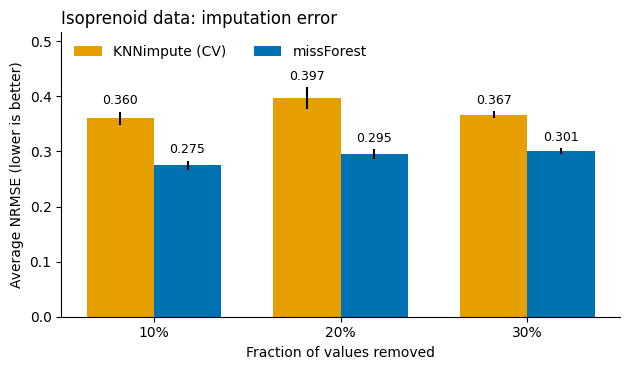

In [14]:
# Figure 1 analogue: average NRMSE per missing rate (error bars: standard error)
c_knn, c_mf = "#E69F00", "#0072B2"      # colour-blind-safe pair (Okabe-Ito)
x = np.arange(len(summary)); w = 0.36
fig, ax = plt.subplots(figsize=(6.4, 3.8))
b1 = ax.bar(x - w / 2, summary.NRMSE_KNN, w, yerr=summary.SE_KNN, color=c_knn, label="KNNimpute (CV)")
b2 = ax.bar(x + w / 2, summary.NRMSE_missForest, w, yerr=summary.SE_missForest, color=c_mf, label="missForest")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set_xticks(x, summary.rate)
ax.set_xlabel("Fraction of values removed"); ax.set_ylabel("Average NRMSE (lower is better)")
ax.set_title("Isoprenoid data: imputation error", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, max(summary.NRMSE_KNN.max(), summary.NRMSE_missForest.max()) * 1.3)
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.tight_layout(); plt.savefig("fig_nrmse.png", dpi=200); plt.show()

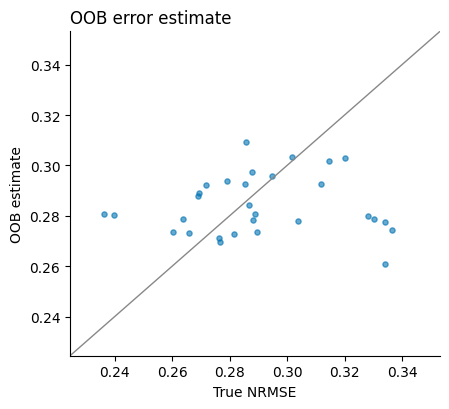

In [15]:
# OOB estimate versus true error (Figure 4 analogue): points near the diagonal mean a good estimate
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.scatter(runs.nrmse_mf, runs.oob_est, s=14, color=c_mf, alpha=0.6)
lim = [min(runs.nrmse_mf.min(), runs.oob_est.min()) * 0.95, max(runs.nrmse_mf.max(), runs.oob_est.max()) * 1.05]
ax.plot(lim, lim, color="#888888", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("True NRMSE"); ax.set_ylabel("OOB estimate")
ax.set_title("OOB error estimate", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_oob.png", dpi=200); plt.show()

## Parameters used

In [16]:
params = pd.DataFrame([
    ("Trees per forest (ntree)", NTREE, "paper: 100"),
    ("Variables tried per split (mtry)", MTRY or int(np.sqrt(p)), "paper: floor(sqrt(p))"),
    ("Maximum iterations", MAXITER, "assumption, the paper only gives the stopping rule"),
    ("Initial imputation", "column mean", "paper: mean imputation or another method"),
    ("Missing rates", ", ".join(f"{r:.0%}" for r in RATES), "paper: 10, 20, 30%"),
    ("Missingness mechanism", "completely at random", "paper"),
    ("Simulation runs per rate", NSIM, "paper: 50"),
    ("KNNimpute k (chosen by CV)", f"{KS.start} to {KS.stop - 1}", "paper: 1 to 15"),
    ("KNNimpute neighbours among", KNN_NEIGHBOURS, "paper: variables"),
    ("KNN CV scheme", "3 x 10% held-out entries", "own choice, paper's Algorithm 2 not reproduced exactly"),
    ("Random seed", SEED, "own choice"),
], columns=["parameter", "value used", "note"])
params

,parameter,value used,note
0,Trees per forest (ntree),100,paper: 100
1,Variables tried per split (mtry),6,paper: floor(sqrt(p))
2,Maximum iterations,10,"assumption, the paper only gives the stopping ..."
3,Initial imputation,column mean,paper: mean imputation or another method
4,Missing rates,"10%, 20%, 30%","paper: 10, 20, 30%"
5,Missingness mechanism,completely at random,paper
6,Simulation runs per rate,10,paper: 50
7,KNNimpute k (chosen by CV),1 to 15,paper: 1 to 15
8,KNNimpute neighbours among,variables,paper: variables
9,KNN CV scheme,3 x 10% held-out entries,"own choice, paper's Algorithm 2 not reproduced..."


## Comparison with the paper

The paper reports the Isoprenoid result only as bars in Fig. 1, not as numbers in the text, so the comparison has to be made against the figure. Things that can be checked directly:

| Item | Paper | This notebook |
|---|---|---|
| missForest vs KNNimpute (Isoprenoid) | missForest lower error | reproduced (`change_vs_KNN`) |
| missForest vs MissPALasso | MissPALasso slightly better on gene expression data | not reproduced (no standard Python implementation) |
| Iterations until stop | about 5 | see `mean_iterations`, from 3.6 - 4.0 |
| OOB estimate vs true error | within a few percent for this dataset | 1.5% - 2.9% see `mean_abs_OOB_deviation` |
| Runtime per imputation | 5.8 s (Table 1) | around 40s see `sec_per_missForest_run` (depends on hardware) |


### Possible reasons for differences
- The authors used the R package *missForest* (randomForest), while this notebook uses scikit-learn forests. Defaults for tree growth and bootstrapping differ slightly.
- The cross-validation for the KNNimpute neighbour count is not identical to the paper's Algorithm 2, and the distance weighting and handling of missing values inside the distance differ between implementations.
- Random missing patterns and seeds differ, so averages over 50 runs differ slightly.
- The OOB scaling and the iteration cap are implementation choices.
- Only KNNimpute is reproduced as comparison method.